- 3.1 Linear Basis Function Models
- 3.2 The Bias-Variance Decomposition
- 3.3 Bayesian Linear Regression
- 3.4 Bayesian Model Comparison
- 3.5 The Evidence Approximation
- 3.6 Limitations of Fixed Basis Functions

# Sequential Bayesian Linear Regression

This notebook aims to reproduce Figure 3.7 from Christopher Bishop's *Pattern Recognition and Machine Learning* (Section 3.3.1). The figure demonstrates how a Bayesian model updates its beliefs about parameters as new data arrives, and how that paramater uncertainty translates into predictive uncertainty in the data space.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from jax.scipy.stats import multivariate_normal

## Step 1: Define the Ground Truth & Hyperparameters

let the true function be $f(x, \mathbf{w}) = w_0 + w_1 x$

In [2]:
# True Weights
w0_true = -0.3
w1_true = 0.5

sigma_noise = 0.2

alpha = 2.0
beta = 1.0 / (sigma_noise **2) # precision_noise

## Step 2: Implement Core Bayesian JAX Functions

Posterior: $$p(\mathbf{w}\vert{}\mathbf{t}) = \mathcal{N}(\mathbf{w}\vert{}\mathbf{m}_N, \mathbf{S}_N)$$

Where:

* $\mathbf{S}_N^{-1} = \alpha \mathbf{I} + \beta \mathbf{\Phi}^T \mathbf{\Phi}$
* $\mathbf{m}_N = \beta \mathbf{S}_N \mathbf{\Phi}^T \mathbf{t}$

Equations (3.49), (3.53), (3.54) from textbook

In [3]:
def compute_posterior(Phi, t, alpha, beta):
    num_features = Phi.shape[1]

    S_N_inv = alpha * jnp.eye(num_features) + beta * (Phi.T @ Phi)

    S_N = jnp.linalg.inv(S_N_inv)
    
    m_N = beta * S_N @ Phi.T @ t

    return m_N, S_N

## Step 3: Setup the Visualization Grid

In [4]:
grid_resolution = 100
w0_vals = jnp.linspace(-1, 1, grid_resolution)
w1_vals = jnp.linspace(-1, 1, grid_resolution)
W0, W1 = jnp.meshgrid(w0_vals, w1_vals)
grid = jnp.stack([W0.flatten(), W1.flatten()], axis=-1)

## Step 4: Data Generation
We draw random points uniformly from $[-1, 1]$ and calculate the target value $t_n = w_0 + w_1 x_n + \epsilon$, where $\epsilon \sim \mathcal{N}(0, \beta^{-1})$.

In [5]:
key = jax.random.PRNGKey(42)

def generate_data(key, n_samples):
    key_x, key_noise = jax.random.split(key)
    
    x = jax.random.uniform(key_x, shape=(n_samples,), minval=-1, maxval=1)
    
    noise = jax.random.normal(key_noise, shape=(n_samples,)) * sigma_noise

    t = w0_true + w1_true * x + noise

    return x, t

x_data, t_data = generate_data(key, 20)

## Step 5: The Sequential Update 

Track the model at each step of *$N = 0$*, *$N = 1$*, *$N = 2$*, and *$N = 20$*

For each step, calculate:
1. Likelihood
2. Posterior
3. Sample Lines

In [10]:
# Initialize our history log and starting parameters
history = []
milestones = [0, 1, 2, 20]

m_N = jnp.zeros(2)
S_N = jnp.eye(2) / alpha

for n in milestones:
    # 1. Initialize a dictionary to store this step's data
    step_data = {'n': n}
    
    # 2. Update Posterior & Calculate Likelihood (if we have data)
    if n > 0:
        Phi_n = jnp.stack([jnp.ones(n), x_data[:n]], axis=-1)
        t_n = t_data[:n]
        m_N, S_N = compute_posterior(Phi_n, t_n, alpha, beta)
        
        # Likelihood of the *newest* single data point
        x_new, t_new = x_data[n-1], t_data[n-1]
        preds_grid = W0 + W1 * x_new  
        Z_likelihood = jax.scipy.stats.norm.pdf(t_new, loc=preds_grid, scale=sigma_noise)
        
        step_data['Z_likelihood'] = Z_likelihood
        step_data['x_obs'] = x_data[:n] # Store observed points for scatter plot
        step_data['t_obs'] = t_data[:n]
    else:
        step_data['Z_likelihood'] = None # No likelihood for the pure prior
        
    # 3. Evaluate Prior/Posterior over the 2D grid
    Z_posterior = multivariate_normal.pdf(grid, mean=m_N, cov=S_N).reshape(grid_resolution, grid_resolution)
    step_data['Z_posterior'] = Z_posterior

    # 4. Sample 6 weight vectors from the current Prior/Posterior
    key, subkey = jax.random.split(key)
    sampled_weights = jax.random.multivariate_normal(subkey, mean=m_N, cov=S_N, shape=(6,))
    step_data['sampled_weights'] = sampled_weights
    
    # 5. Save step to history
    history.append(step_data)

print(f"Computation complete. Logged {len(history)} milestones.")

Computation complete. Logged 4 milestones.


## Step 7: Visualization

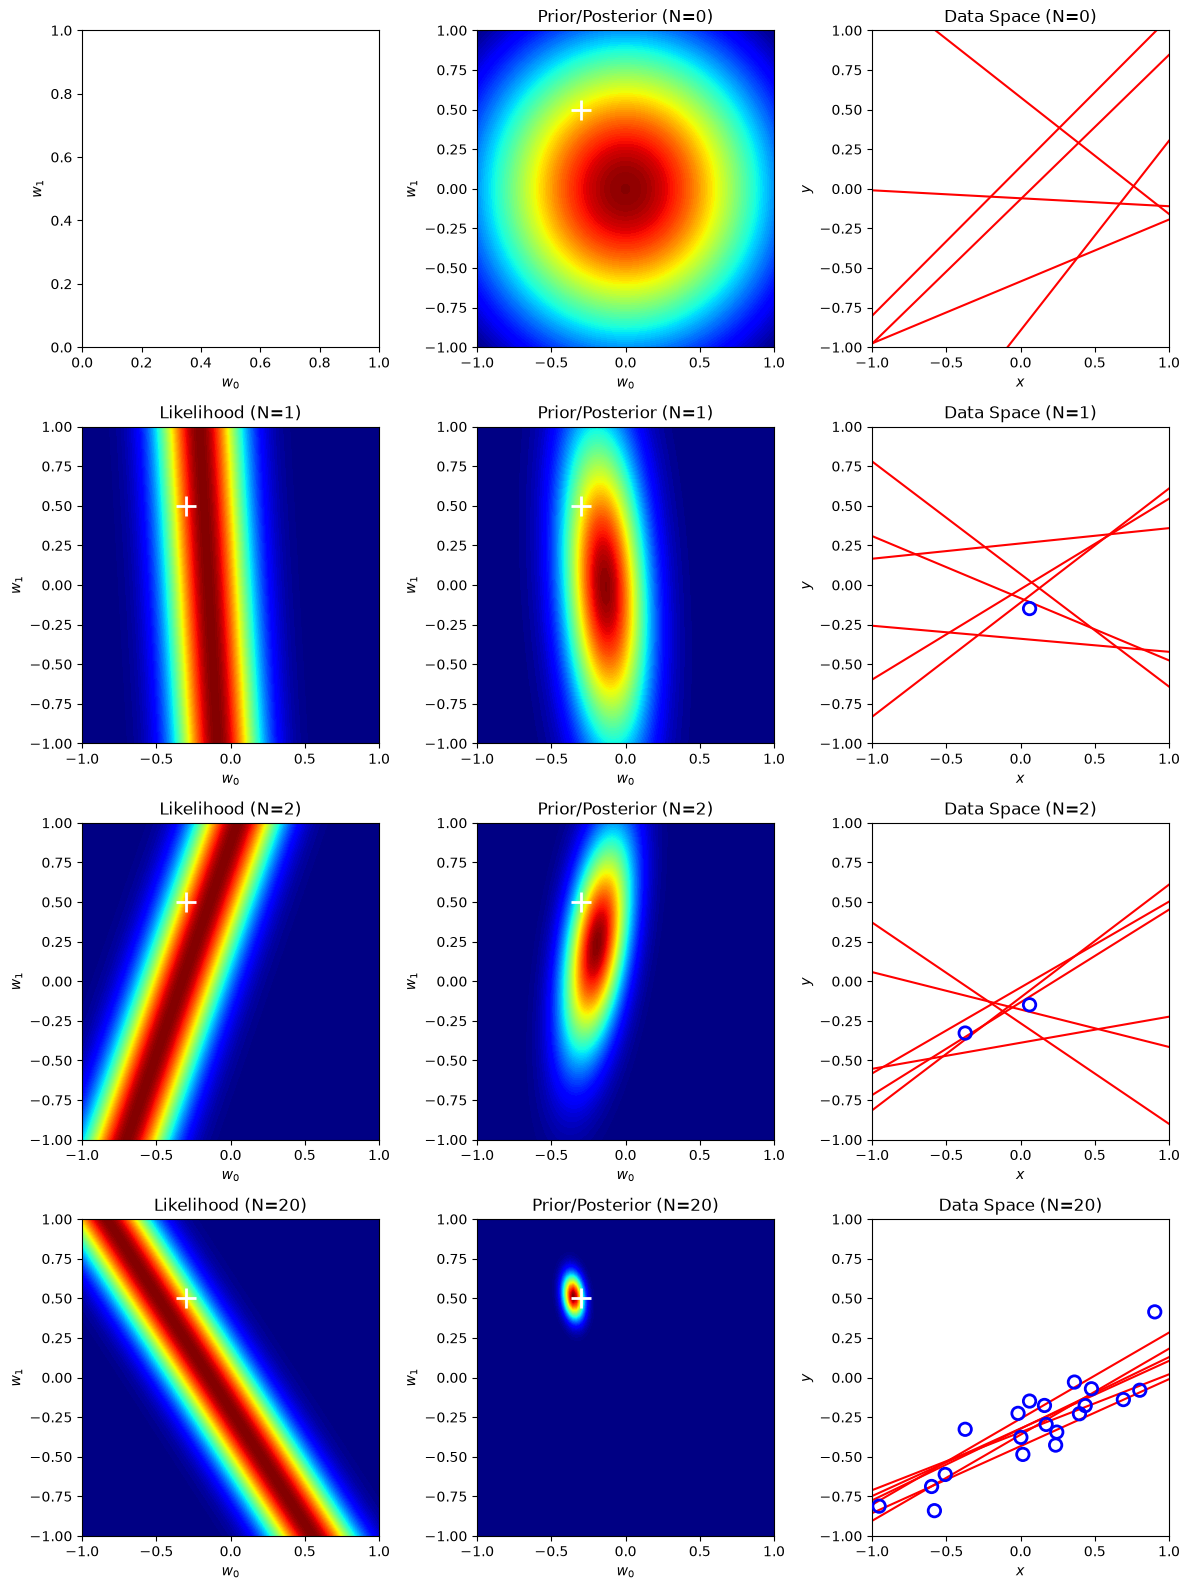

In [11]:
# Create the 4x3 Matplotlib figure
fig, axes = plt.subplots(4, 3, figsize=(12, 16))
fig.subplots_adjust(hspace=0.4, wspace=0.3)

for i, step in enumerate(history):
    n = step['n']
    
    # --- Column 1: Likelihood ---
    ax_lik = axes[i, 0]
    if step['Z_likelihood'] is not None:
        ax_lik.contourf(W0, W1, step['Z_likelihood'], 100, cmap='jet')
        ax_lik.scatter(w0_true, w1_true, marker='+', color='white', s=200, linewidths=2)
        ax_lik.set_title(f'Likelihood (N={n})')
    
    ax_lik.set_xlabel('$w_0$')
    ax_lik.set_ylabel('$w_1$')
    
    # --- Column 2: Prior/Posterior ---
    ax_post = axes[i, 1]
    ax_post.contourf(W0, W1, step['Z_posterior'], 100, cmap='jet')
    ax_post.scatter(w0_true, w1_true, marker='+', color='white', s=200, linewidths=2)
    ax_post.set_xlabel('$w_0$')
    ax_post.set_ylabel('$w_1$')
    ax_post.set_title(f'Prior/Posterior (N={n})')

    # --- Column 3: Data Space ---
    ax_data = axes[i, 2]
    x_plot = jnp.linspace(-1, 1, 100)
    
    # Plot the 6 sampled lines
    for w in step['sampled_weights']:
        y_plot = w[0] + w[1] * x_plot
        ax_data.plot(x_plot, y_plot, 'r-')
        
    # Plot the actual data points observed
    if n > 0:
        ax_data.scatter(step['x_obs'], step['t_obs'], facecolors='none', edgecolors='blue', s=80, linewidths=2, zorder=5)
        
    ax_data.set_xlim(-1, 1)
    ax_data.set_ylim(-1, 1)
    ax_data.set_xlabel('$x$')
    ax_data.set_ylabel('$y$')
    ax_data.set_title(f'Data Space (N={n})')

plt.tight_layout()
plt.show()